# 03 · Congestion pricing: what changed for Uber and Lyft?

On **5 January 2025** New York began charging a fee on vehicles entering Manhattan south of
60th Street (the Congestion Relief Zone, CRZ). High-volume for-hire trips that begin, end
or pass through the zone pay **$1.50 per trip**, collected from the rider.

**Business question for the GM:** did congestion pricing cost us trips in the zone, and did
it change price, wait time or driver earnings there?

**Method:** a simple difference-in-differences.

* Treated: trips that start or end in the CRZ (zone list in `reference/zone_attributes.csv`)
* Control: all other NYC trips, same company, same weeks
* Pre-period: weeks starting 4 Nov to 16 Dec 2024. Post-period: weeks starting 13 Jan to 24 Mar 2025.
  The holiday weeks and the launch week are left out of both.

Seasonality hits both groups, so comparing CRZ growth with non-CRZ growth removes most of it.
The result is still an estimate, not a causal proof. See the caveats at the end.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import duckdb
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio
pio.renderers.default = "plotly_mimetype+png"   # interactive in VS Code + a static image GitHub can display

from metrics.kpi import compute_kpis, kpi_sql

con = duckdb.connect(str(ROOT / "data" / "warehouse.duckdb"), read_only=True)
PRE = ("2024-11-04", "2024-12-16")
POST = ("2025-01-13", "2025-03-24")
pd.options.display.float_format = "{:,.4f}".format

## 1. Does our CRZ zone list match where the fee was actually charged?

This checks our definition against the data before using it. Trips that start in a
Manhattan zone and end in another borough should be charged if, and only if, the pickup
zone is in the CRZ.

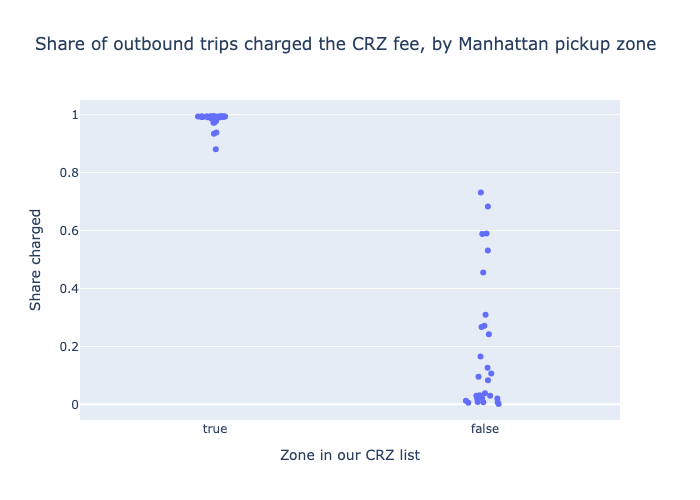

,pu_zone_id,zone,borough,is_crz,trips_to_outer_boroughs,pct_charged_cbd_fee
0,13,Battery Park City,Manhattan,True,47310,0.8803
61,43,Central Park,Manhattan,False,11217,0.5308
62,143,Lincoln Square West,Manhattan,False,41526,0.5882
63,141,Lenox Hill West,Manhattan,False,87574,0.5900
64,237,Upper East Side South,Manhattan,False,88644,0.6832
65,142,Lincoln Square East,Manhattan,False,71726,0.7310


In [2]:
val = con.execute("select * from crz_zone_validation order by is_crz desc, pct_charged_cbd_fee").df()
px.strip(val, x="is_crz", y="pct_charged_cbd_fee", hover_name="zone",
         title="Share of outbound trips charged the CRZ fee, by Manhattan pickup zone",
         labels={"is_crz": "Zone in our CRZ list", "pct_charged_cbd_fee": "Share charged"}).show()
val[(val["is_crz"] & (val["pct_charged_cbd_fee"] < 0.9)) | (~val["is_crz"] & (val["pct_charged_cbd_fee"] > 0.5))]

**What the full build found:** every CRZ zone is charged on 88–97% of outbound trips.
Several zones just *north* of 60th St are charged 53–73% of the time: Lincoln Square,
Lenox Hill West, Upper East Side South and Central Park. That isn't an error in the list.
Those riders drive *through* the zone to reach Brooklyn or Queens, and the fee also applies
to through-trips. So the list is right, and through-trips are a real source of control-group
contamination (see caveats).

## 2. Weekly trips, CRZ vs the rest of NYC

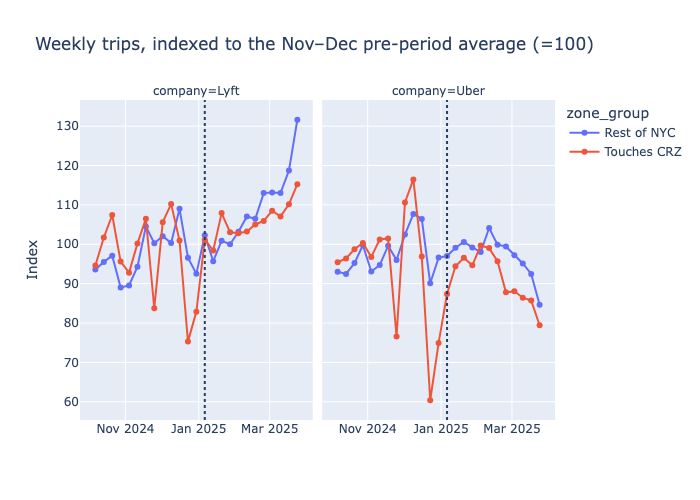

In [3]:
weekly = con.execute(f"""
    select pickup_week, company, touches_crz,
           {kpi_sql('trips')} as trips,
           {kpi_sql('avg_fare')} as avg_fare,
           {kpi_sql('avg_wait_min')} as avg_wait_min,
           {kpi_sql('driver_earnings_per_engaged_hour')} as earnings_per_hr,
           {kpi_sql('cbd_fee_revenue')} as cbd_fee
    from gold_weekly_crz_company
    where pickup_week >= '2024-10-07' and pickup_week <= '2025-03-24'   -- complete weeks only
    group by all order by pickup_week
""").df()
weekly["zone_group"] = np.where(weekly["touches_crz"], "Touches CRZ", "Rest of NYC")
weekly["pickup_week"] = pd.to_datetime(weekly["pickup_week"]).dt.strftime("%Y-%m-%d")
pre_avg = (weekly[weekly["pickup_week"].between(*PRE)].groupby(["company", "zone_group"])["trips"].mean()
           .rename("pre_avg").reset_index())
weekly = weekly.merge(pre_avg, on=["company", "zone_group"])
weekly["trips_index"] = weekly["trips"] / weekly["pre_avg"] * 100

fig = px.line(weekly, x="pickup_week", y="trips_index", color="zone_group", facet_col="company", markers=True,
              title="Weekly trips, indexed to the Nov–Dec pre-period average (=100)",
              labels={"trips_index": "Index", "pickup_week": ""})
fig.add_vline(x="2025-01-06", line_dash="dot")
fig.show()

## 3. Difference-in-differences estimate

In [4]:
def period(df):
    return np.select([df["pickup_week"].between(*PRE), df["pickup_week"].between(*POST)], ["pre", "post"], None)

w = weekly.assign(period=period(weekly)).dropna(subset=["period"])
avg = w.groupby(["company", "zone_group", "period"])[["trips", "avg_fare", "avg_wait_min", "earnings_per_hr"]].mean().unstack("period")

rows = []
for company in ["Uber", "Lyft"]:
    for metric in ["trips", "avg_fare", "avg_wait_min", "earnings_per_hr"]:
        crz = avg.loc[(company, "Touches CRZ"), metric]
        rest = avg.loc[(company, "Rest of NYC"), metric]
        g_crz, g_rest = crz["post"] / crz["pre"] - 1, rest["post"] / rest["pre"] - 1
        rows.append({"company": company, "metric": metric, "crz_change": g_crz, "rest_change": g_rest,
                     "did_estimate_pts": (g_crz - g_rest) * 100})
did = pd.DataFrame(rows)
did.style.format({"crz_change": "{:+.1%}", "rest_change": "{:+.1%}", "did_estimate_pts": "{:+.1f} pts"})

,company,metric,crz_change,rest_change,did_estimate_pts
0,Uber,trips,-8.4%,-2.7%,-5.7 pts
1,Uber,avg_fare,-8.0%,-0.8%,-7.2 pts
2,Uber,avg_wait_min,-8.0%,-1.2%,-6.8 pts
3,Uber,earnings_per_hr,-0.4%,+0.3%,-0.8 pts
4,Lyft,trips,+6.1%,+9.3%,-3.2 pts
5,Lyft,avg_fare,-11.5%,-4.1%,-7.4 pts
6,Lyft,avg_wait_min,-15.4%,-10.7%,-4.7 pts
7,Lyft,earnings_per_hr,+1.7%,+0.8%,+0.9 pts


`did_estimate_pts` is how much faster (positive) or slower (negative) the CRZ metric changed
than the same metric outside the zone, in percentage points.

## 4. Fee collected

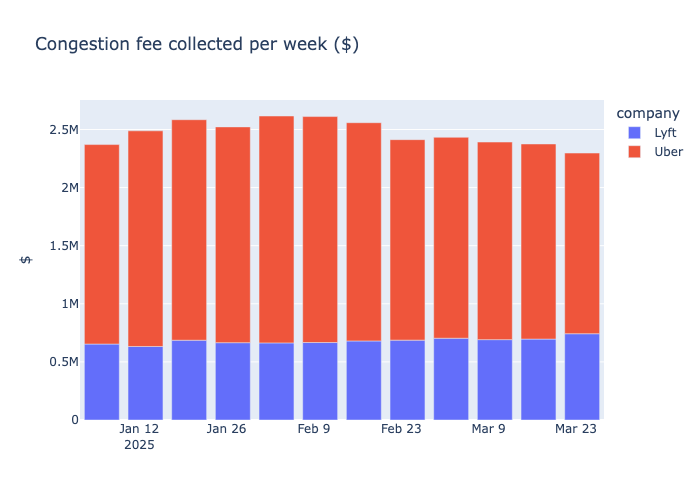

Total collected Jan–Mar 2025: $29,660,164


In [5]:
fees = weekly[weekly["pickup_week"] >= "2025-01-06"].groupby(["pickup_week", "company"])["cbd_fee"].sum().reset_index()
px.bar(fees, x="pickup_week", y="cbd_fee", color="company", title="Congestion fee collected per week ($)",
       labels={"cbd_fee": "$", "pickup_week": ""}).show()
print(f"Total collected Jan–Mar 2025: ${fees['cbd_fee'].sum():,.0f}")

## 5. Which CRZ zones moved most?

In [6]:
daily = con.execute("""
    select g.*, z.zone, z.is_crz from gold_daily_zone_company g join dim_zone z on z.zone_id = g.pu_zone_id
    where z.borough = 'Manhattan'
""").df()
daily["pickup_week"] = pd.to_datetime(daily["pickup_week"]).dt.strftime("%Y-%m-%d")
daily["period"] = period(daily)
z = compute_kpis(daily.dropna(subset=["period"]), ["zone", "is_crz", "period"], ["trips", "avg_wait_min"])
weeks = {"pre": 7, "post": 11}
z["trips_per_week"] = z["trips"] / z["period"].map(weeks)
zp = z.pivot_table(index=["zone", "is_crz"], columns="period", values="trips_per_week").reset_index()
zp["change"] = zp["post"] / zp["pre"] - 1
zp[zp["pre"] > 2000].sort_values("change").head(10)

period,zone,is_crz,post,pre,change
6,Central Park,False,"5,739.9091","7,319.0000",-0.2158
30,Lincoln Square East,False,"30,647.8182","34,785.8571",-0.1190
47,Seaport,True,"9,768.3636","10,957.2857",-0.1085
59,Upper West Side South,False,"28,842.4545","32,253.7143",-0.1058
57,Upper East Side South,False,"38,515.8182","42,775.5714",-0.0996
65,Yorkville East,False,"16,688.3636","18,496.8571",-0.0978
56,Upper East Side North,False,"33,459.5455","36,958.4286",-0.0947
15,Financial District South,True,"11,193.9091","12,347.1429",-0.0934
40,Midtown North,True,"38,285.1818","41,942.4286",-0.0872
19,Gramercy,True,"36,194.2727","39,571.7143",-0.0853


## Caveats to state in any readout

* **No untreated twin.** Outer-borough trips are a reasonable control, but they have their
  own seasonality, and weather affects the two groups differently.
* **Through-trips** pay the fee without starting or ending in the zone. They sit in the
  control group, which biases the estimate towards zero.
* **Completed trips only.** The data has no requests that were never fulfilled, so a drop in
  demand can't be separated from a drop in supply.
* **Short post-period:** 11 weeks. A real readout would revisit this after a year, with
  year-over-year comparisons.